# Healthcare Data Analysis Project
Dataset: Healthcare Dataset (Kaggle)

Tools: Pandas, Numpy, Matplotlib, Seaborn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Loading the Data


In [2]:
df = pd.read_csv("healthcare_dataset.csv")
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


## Understanding the Data

In [3]:
print(df.shape)       # rows and columns
df.info()             # column names and types
df.head()             # first 5 rows
df.describe()         # numbers summary

(55500, 15)
<class 'pandas.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  str    
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  str    
 3   Blood Type          55500 non-null  str    
 4   Medical Condition   55500 non-null  str    
 5   Date of Admission   55500 non-null  str    
 6   Doctor              55500 non-null  str    
 7   Hospital            55500 non-null  str    
 8   Insurance Provider  55500 non-null  str    
 9   Billing Amount      55500 non-null  float64
 10  Room Number         55500 non-null  int64  
 11  Admission Type      55500 non-null  str    
 12  Discharge Date      55500 non-null  str    
 13  Medication          55500 non-null  str    
 14  Test Results        55500 non-null  str    
dtypes: float64(1), int64(2), str(12)
memory usage: 6.4 M

,Age,Billing Amount,Room Number
count,55500.000000,55500.000000,55500.000000
mean,51.539459,25539.316097,301.134829
std,19.602454,14211.454431,115.243069
min,13.000000,-2008.492140,101.000000
25%,35.000000,13241.224652,202.000000
50%,52.000000,25538.069376,302.000000
75%,68.000000,37820.508436,401.000000
max,89.000000,52764.276736,500.000000


## Data Cleaning

In [4]:
df.isnull().sum()     # missing values


Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64

In [5]:
df.duplicated().sum() # duplicate rows

np.int64(534)

In [6]:
df = df.drop_duplicates()
df["Name"] = df["Name"].str.title()
df["Date of Admission"] = pd.to_datetime(df["Date of Admission"])
df["Discharge Date"] = pd.to_datetime(df["Discharge Date"])

## Feature Engineering

In [7]:
df["Stay Days"] = (df["Discharge Date"] - df["Date of Admission"]).dt.days
df["Year"] = df["Date of Admission"].dt.year
df["Month"] = df["Date of Admission"].dt.month_name()
df["Age Group"] = pd.cut(df["Age"], bins=[0, 18, 35, 50, 65, 100],
                         labels=["0-18", "19-35", "36-50", "51-65", "65+"])
df["Bill Level"] = np.where(df["Billing Amount"] > df["Billing Amount"].mean(), "High", "Low")
df["Bill Level"].value_counts()

Bill Level
Low     27487
High    27479
Name: count, dtype: int64

## Data Transformation and Analysis

In [8]:
# 1. Which medical condition has the highest average bill?
df.groupby("Medical Condition")["Billing Amount"].mean().sort_values(ascending=False)

Medical Condition
Obesity         25804.361902
Diabetes        25660.478635
Asthma          25633.461696
Arthritis       25511.783246
Hypertension    25503.058720
Cancer          25152.322947
Name: Billing Amount, dtype: float64

In [9]:
# 2. Which insurance company has the highest total billing?
df.groupby("Insurance Provider")["Billing Amount"].sum().sort_values(ascending=False)

Insurance Provider
Cigna               2.843341e+08
Medicare            2.829110e+08
Blue Cross          2.804091e+08
UnitedHealthcare    2.799154e+08
Aetna               2.764987e+08
Name: Billing Amount, dtype: float64

In [10]:
# 3. How many days do patients stay on average?
df["Stay Days"].mean()

np.float64(15.499290470472657)

In [11]:
# 4. Which month has the most admissions?
df["Month"].value_counts()

Month
August       4785
July         4765
January      4655
June         4650
March        4622
December     4617
October      4613
May          4555
September    4508
November     4508
April        4478
February     4210
Name: count, dtype: int64

In [12]:
# 5. How many patients are in each admission type?
df["Admission Type"].value_counts()

Admission Type
Elective     18473
Urgent       18391
Emergency    18102
Name: count, dtype: int64

In [13]:
# 6. Which admission type costs the most?
df.groupby("Admission Type")["Billing Amount"].mean().sort_values(ascending=False)

Admission Type
Elective     25612.139673
Urgent       25514.532045
Emergency    25505.332240
Name: Billing Amount, dtype: float64

In [14]:
# 7. Which age group has the most patients?
df["Age Group"].value_counts()

Age Group
65+      16096
19-35    13519
51-65    12298
36-50    12167
0-18       886
Name: count, dtype: int64

In [15]:
pivot = pd.pivot_table(df, values="Billing Amount", index="Medical Condition",
                       columns="Admission Type", aggfunc="mean")
pivot

Admission Type,Elective,Emergency,Urgent
Medical Condition,,,
Arthritis,25479.594414,25497.105308,25558.383152
Asthma,25253.907794,25893.700903,25761.368051
Cancer,25671.842589,24867.223527,24900.213960
Diabetes,26032.124899,25471.610170,25484.651031
Hypertension,25555.088835,25471.370388,25479.248755
Obesity,25687.732672,25820.553648,25903.815124


# Data Visualization

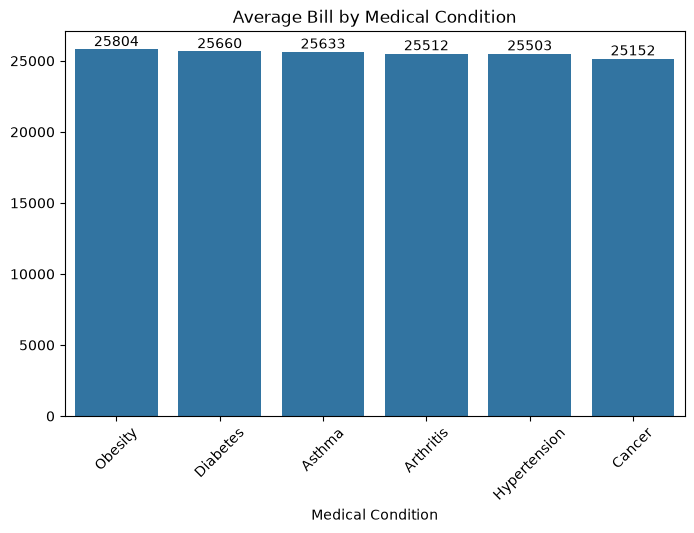

In [16]:
avg_bill = df.groupby("Medical Condition")["Billing Amount"].mean().sort_values(ascending=False)
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=avg_bill.index, y=avg_bill.values)
ax.bar_label(ax.containers[0], fmt="%.0f")
plt.title("Average Bill by Medical Condition")
plt.xticks(rotation=45)
plt.show()

**Insight:** Obesity has the highest average bill (about 25,804), but all conditions are very close to each other.

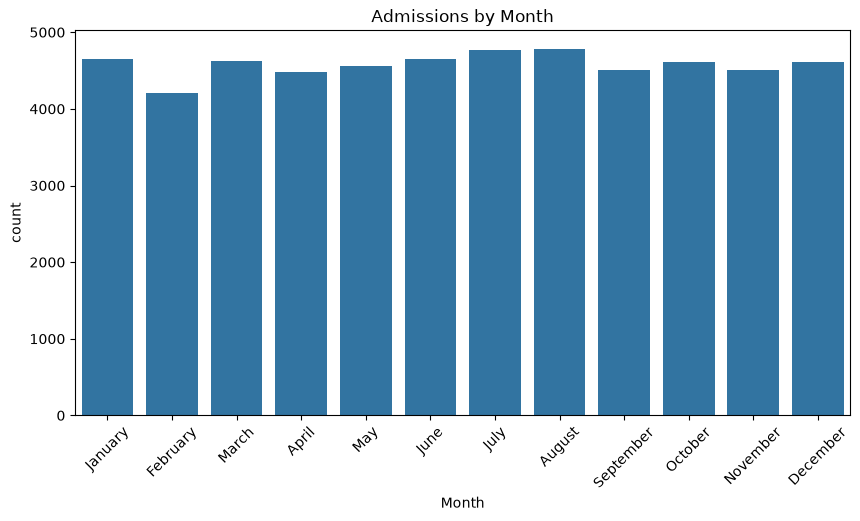

In [17]:
order = ["January","February","March","April","May","June","July",
         "August","September","October","November","December"]
plt.figure(figsize=(10, 5))
sns.countplot(x="Month", data=df, order=order)
plt.title("Admissions by Month")
plt.xticks(rotation=45)
plt.show()

**Insight:** August has the most admissions (4,785) and February has the fewest (4,210).

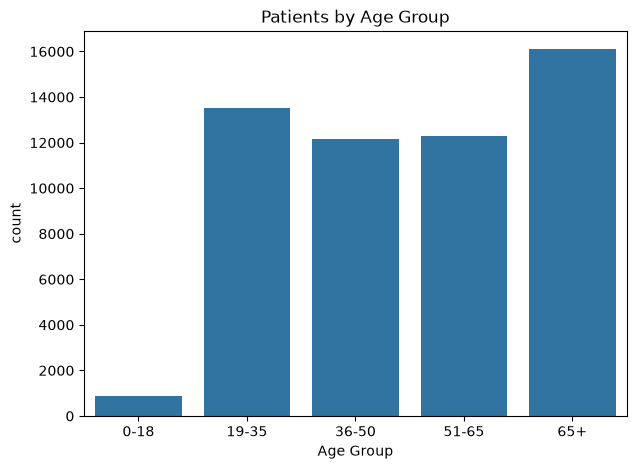

In [18]:
plt.figure(figsize=(7, 5))
sns.countplot(x="Age Group", data=df, order=["0-18","19-35","36-50","51-65","65+"])
plt.title("Patients by Age Group")
plt.show()

**Insight:** The 65+ group has the most patients (16,096). The 0-18 group has the fewest (886).

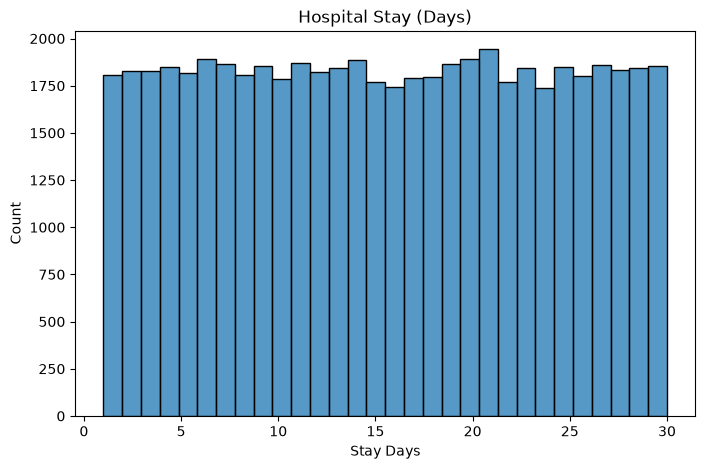

In [19]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Stay Days"], bins=30)
plt.title("Hospital Stay (Days)")
plt.show()

**Insight:** Patients stay about 15.5 days on average. The chart is almost flat, so every stay length from 1 to 30 days is about equally common.

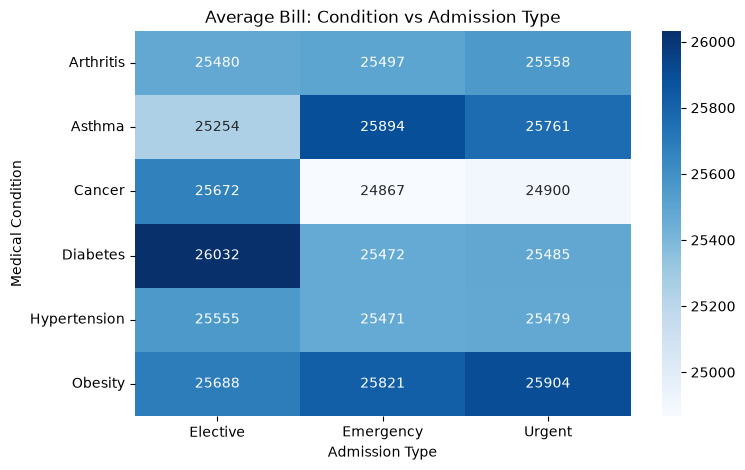

In [20]:
plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Blues")
plt.title("Average Bill: Condition vs Admission Type")
plt.show()

**Insight:** The average bill is almost the same for every condition and admission type. The highest is Diabetes with Elective admission, about 26,032.

In [21]:
pivot.stack().idxmax()


('Diabetes', 'Elective')

# Key Insights
1. Obesity has the highest average bill, but all medical conditions are very close (about 25,150 to 25,800).
2. Cigna has the highest total billing, followed by Medicare and Blue Cross.
3. Patients stay in the hospital about 15.5 days on average.
4. August has the most admissions and February has the fewest.
5. Elective admissions have the highest average bill, but the three admission types are almost equal.
6. The 65+ age group has the most patients, and the 0-18 group has the fewest.

# Conclusion
I cleaned the healthcare data, made new columns, and found patterns in billing, stay time, and admissions. The data is synthetic, so most values look very even.